# Two-Stage Anchor-Based Baseline: Faster R-CNN

**Goal.** Train `fasterrcnn_resnet50_fpn_v2` from COCO weights with a 9-class head (8 VisDrone classes + background) on the clip-level train split, under the fixed preprocessing protocol locked in nb02. Evaluate on the **full val split** using **ignore-aware COCO metrics**. Produce a reproducible baseline against which nb04 (tuning), nb05–nb09 (other detector families), and nb11 (final pipeline) will be compared.

**What this notebook is:** the *untuned* baseline. Hyperparameter tuning is deliberately deferred to nb04.
**What this notebook is not:** the leaderboard submission. That is nb12.

**Protocol (locked):**
- Strategy + size: read from `chosen_preprocessing.json` (should be `letterbox-1280`).
- Split: read from `splits/train_clips.txt` and `splits/val_clips.txt`.
- Eval GT: **full val**, ignore-aware (`gt_fullval_ignore.json`, generated once here and reused downstream).
- Augmentation: HorizontalFlip (p=0.5), RandomScale (0.8–1.25), ColorJitter, RandomBrightnessContrast. No rotation, no random crops (both destroy small objects).
- Ignore masking during training: anchors overlapping ignore regions are assigned label `-1` via the custom RPN assigner from `common.py`.

**Artifacts to publish after training:**
- `fasterrcnn_baseline_best.pth`, `fasterrcnn_baseline_last.pth`
- `metrics_fasterrcnn_baseline.json` (metrics + config + W&B URL)
- `gt_fullval_ignore.json`, `gt_fullval_noignore.json`
- `val_preds_baseline_ignore.json` (reused by nb10 TIDE, nb11 WBF, nb13 temporal)
- `failure_case_1.png`, `failure_case_2.png`, `failure_case_3.png`

## 1. Setup

Paths, imports, seeds, and verification that the nb02 artifacts are present.

In [1]:
import sys, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from tqdm.auto import tqdm

COMP_DIR    = Path("/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026")
DATASET_DIR = Path("/kaggle/input/datasets/suchok/my-dataset")
OUTPUTS_DIR = Path("/kaggle/input/datasets/suchok/outputs")
WORK_DIR    = Path("/kaggle/working")

assert COMP_DIR.exists(),    f"missing competition: {COMP_DIR}"
assert DATASET_DIR.exists(), f"missing my-dataset: {DATASET_DIR}"
assert OUTPUTS_DIR.exists(), f"missing outputs-2 (nb02 artifacts): {OUTPUTS_DIR}"

WORK_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(DATASET_DIR))
import common, importlib
importlib.reload(common)
from common import *

set_seeds(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("DEVICE:", DEVICE, "| torch:", torch.__version__)

DEVICE: cuda | torch: 2.11.0+cu130


## 2. Load the locked protocol from nb02

Read `chosen_preprocessing.json`, the split lists, and assert that the eval GT files are present. If any of these fail, nb02 was not published correctly and this notebook cannot continue.

In [2]:
chosen = json.load(open(OUTPUTS_DIR / "chosen_preprocessing.json"))
STRAT  = chosen["strategy"]
SIZE   = int(chosen["size"])
print("Locked preprocessing:", STRAT, SIZE)

train_clips, val_clips = load_splits(OUTPUTS_DIR / "splits")
print(f"clips: train={len(train_clips)}  val={len(val_clips)}")
assert set(train_clips).isdisjoint(set(val_clips))

TRAIN_DIR = COMP_DIR / "train"
VAL_DIR   = COMP_DIR / "val"
TEST_CSV  = COMP_DIR / "test_images.csv"

train_index = filter_by_clips(index_split(TRAIN_DIR), train_clips)
val_index   = filter_by_clips(index_split(VAL_DIR),   val_clips)

print(f"frames: train={len(train_index):,}  val={len(val_index):,}")
assert len(train_index) > 0 and len(val_index) > 0

Locked preprocessing: letterbox 1280


clips: train=56  val=7


frames: train=24,201  val=2,846


## 3. Build full-val GT files (once)

`nb02` produced GT for the 200-frame subset only — that was for the preprocessing ablation. For model benchmarking we need GT on the **full val set** (2,846 frames). We build both ignore-aware and no-ignore versions here and reuse them in every later notebook.

In [3]:
gt_fullval_ignore   = WORK_DIR / "gt_fullval_ignore.json"
gt_fullval_noignore = WORK_DIR / "gt_fullval_noignore.json"

if not gt_fullval_ignore.exists():
    build_fullval_gt(val_index, str(gt_fullval_ignore),   include_ignore=True)
if not gt_fullval_noignore.exists():
    build_fullval_gt(val_index, str(gt_fullval_noignore), include_ignore=False)

def _count(p):
    d = json.load(open(p))
    n0 = sum(a["iscrowd"] == 0 for a in d["annotations"])
    n1 = sum(a["iscrowd"] == 1 for a in d["annotations"])
    return n0, n1

m0, c0 = _count(gt_fullval_ignore)
print(f"gt_fullval_ignore  : {m0:,} normal, {c0:,} crowd")
print(f"gt_fullval_noignore: {len(json.load(open(gt_fullval_noignore))['annotations']):,} normal, 0 crowd")

gt_fullval_ignore  : 114,132 normal, 3,995 crowd


gt_fullval_noignore: 114,132 normal, 0 crowd


## 4. Dataset smoke test (must pass before training)

Instantiate the dataset on a few training frames, verify that boxes are inside the network canvas, labels are in `1..8`, and `ignore_boxes` carries through. Visualize one sample with GT + ignore regions drawn on the letterboxed canvas. This cell catches label-mapping and box-scaling bugs **before** spending GPU hours.

In [4]:
import albumentations as A

train_transforms = A.Compose(
    [
        A.HorizontalFlip(p=0.5),
        A.RandomScale(scale_limit=(-0.2, 0.25), p=0.5),
        A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
        A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=20, val_shift_limit=10, p=0.3),
    ],
    bbox_params=A.BboxParams(
        format="pascal_voc",
        label_fields=["labels"],
        min_visibility=0.3,
    ),
)

train_ds = VisDroneDetectionDataset(
    train_index.head(8), STRAT, SIZE, is_train=True, transforms=train_transforms,
)
val_ds = VisDroneDetectionDataset(
    val_index.head(8), STRAT, SIZE, is_train=False, transforms=None,
)

img_t, target = train_ds[0]
print("image tensor:", tuple(img_t.shape), "| dtype:", img_t.dtype)
print("labels:", target["labels"].tolist())
print("boxes shape:", tuple(target["boxes"].shape),
      "| ignore_boxes shape:", tuple(target["ignore_boxes"].shape))

assert target["labels"].min() >= 1 and target["labels"].max() <= 8, \
    f"labels must be 1..8 (bg=0), got {target['labels'].tolist()}"
assert (target["boxes"][:, 2] > target["boxes"][:, 0]).all()
assert (target["boxes"][:, 3] > target["boxes"][:, 1]).all()
assert target["boxes"].max() <= SIZE + 1, "boxes must fit in canvas"
print("smoke OK")

image tensor: (3, 1280, 1280) | dtype: torch.float32
labels: [1, 1, 6, 1, 1, 8, 1, 8, 8, 8, 1, 1, 1, 1, 1, 1, 1, 8, 8, 1, 1, 1, 8]
boxes shape: (23, 4) | ignore_boxes shape: (4, 4)
smoke OK


### Visual sanity check on one training sample

Draw GT boxes (green), ignore regions (blue), and confirm alignment with the resized image.

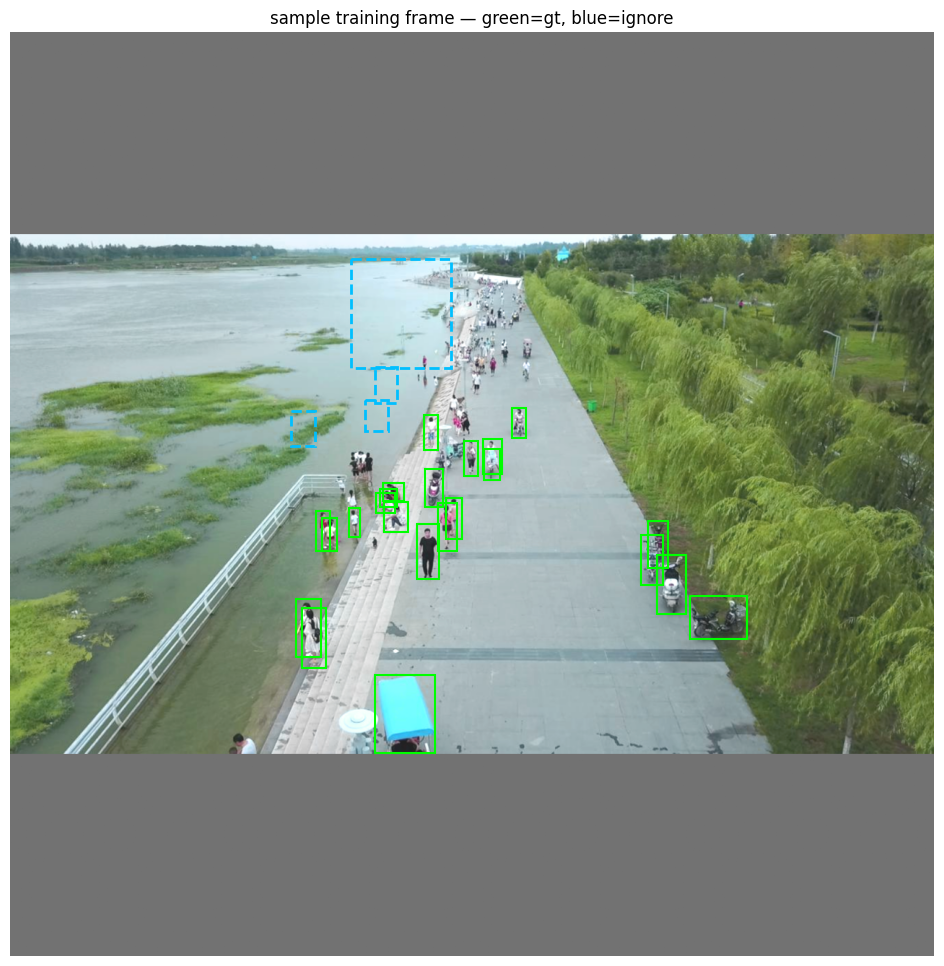

In [5]:
def denorm(t):
    m = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    s = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (t * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

vis = denorm(img_t).copy()
fig, ax = plt.subplots(1, 1, figsize=(12, 12))
ax.imshow(vis)
for x1, y1, x2, y2 in target["boxes"].numpy():
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                   edgecolor="lime", facecolor="none", lw=1.5))
for x1, y1, x2, y2 in target["ignore_boxes"].numpy():
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                   edgecolor="deepskyblue", facecolor="none", lw=2, ls="--"))
ax.set_title("sample training frame — green=gt, blue=ignore")
ax.axis("off"); plt.show()

## 5. Model construction

`fasterrcnn_resnet50_fpn_v2` pretrained on COCO, head replaced with `FastRCNNPredictor(in_features, 9)`. The pretrained weights (checkpoint `fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth`) are loaded **before** the head swap so all backbone and RPN weights transfer cleanly; only the box predictor is reinitialised.

In [6]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

weight_path = list(DATASET_DIR.glob("fasterrcnn_resnet50_fpn_v2_coco*.pth"))[0]
print("Loading weights:", weight_path.name)

model = fasterrcnn_resnet50_fpn_v2(weights=None, weights_backbone=None)
model.load_state_dict(torch.load(weight_path, map_location="cpu"))

in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES + 1)
model.to(DEVICE)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable params: {n_params/1e6:.1f}M")

Loading weights: fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


trainable params: 43.3M


## 6. Ignore-aware RPN monkey-patch

The default `RegionProposalNetwork` uses `Matcher(0.7, 0.3)` with no notion of ignore regions. Anchors that fall inside crowd/parking-lot regions are trained as **negatives**, which teaches the model to suppress real objects that were never annotated. We wrap the assigner so that any anchor with IoU > 0.3 to an ignore region is labelled `-1` (ignored by the sampler, contributes no loss).

This is the training-time counterpart to the `iscrowd=1` handling in the evaluator.

In [7]:
from torchvision.ops import box_iou
from torchvision.models.detection._utils import Matcher

class IgnoreAwareAssigner(torch.nn.Module):
    """Wraps a Matcher; needs the current target's ignore_boxes at forward time.

    Usage: at each training step, set `assigner.current_ignore_boxes = target["ignore_boxes"]`
    before calling `model(images, targets)`. Then `forward(anchors, gt_boxes)` is called by
    the RPN internally.
    """
    def __init__(self, high_thresh=0.5, low_thresh=0.4, ignore_iou_thresh=0.3):
        super().__init__()
        self.matcher = Matcher(high_thresh, low_thresh, allow_low_quality_matches=True)
        self.ignore_iou_thresh = ignore_iou_thresh
        self.current_ignore_boxes = None

    def forward(self, anchors, gt_boxes):
        matched_labels, matched_boxes = self.matcher(anchors, gt_boxes)
        if self.current_ignore_boxes is None or len(self.current_ignore_boxes) == 0:
            return matched_labels, matched_boxes
        if len(gt_boxes) == 0:
            return matched_labels, matched_boxes
        matched_labels = matched_labels.clone()
        iou = box_iou(anchors, self.current_ignore_boxes).max(dim=1).values
        ignored = (iou > self.ignore_iou_thresh) & (matched_labels >= 0)
        matched_labels[ignored] = -1
        return matched_labels, matched_boxes


rpn_assigner = IgnoreAwareAssigner().to(DEVICE)
model.rpn.box_assigner = rpn_assigner
print("RPN assigner wrapped:", type(model.rpn.box_assigner).__name__)

RPN assigner wrapped: IgnoreAwareAssigner


### Verification: forward + backward pass

One-batch forward and backward. Confirms the model, the wrapped assigner, and the dataset all wire together. Any error here means stop; do not start the training loop.

In [8]:
sample_idx = 0
img_t, target = train_ds[sample_idx]
rpn_assigner.current_ignore_boxes = target["ignore_boxes"].to(DEVICE)

model.train()
loss_dict = model(
    [img_t.to(DEVICE)],
    [{k: v.to(DEVICE) for k, v in target.items()
      if k in ("boxes", "labels", "image_id", "area", "iscrowd")}],
)
loss = sum(loss_dict.values())
print("loss terms:", {k: float(v) for k, v in loss_dict.items()})
print("total loss:", float(loss))
assert torch.isfinite(loss), "loss is not finite"
loss.backward()
print("backward OK")

/tmp/ipykernel_23/3224561898.py:12: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  print("loss terms:", {k: float(v) for k, v in loss_dict.items()})


loss terms: {'loss_classifier': 2.3196330070495605, 'loss_box_reg': 0.6736314296722412, 'loss_objectness': 0.2517092823982239, 'loss_rpn_box_reg': 0.16240569949150085}
total loss: 3.407379388809204


backward OK


## 7. Optimizer, schedule, and DataLoaders

SGD with momentum (torchvision Faster R-CNN defaults), StepLR every 3 epochs with gamma 0.1. Batch size 2 at 1280 resolution on T4/L4 (falls back to 1 on OOM). The schedule is intentionally the torchvision default — nb04 tests alternatives.

In [9]:
import numpy as np
import cv2
import torch
from torch.utils.data import DataLoader
from torchvision.transforms import functional as TF
import common

class SafeVisDroneDataset(common.VisDroneDetectionDataset):
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = cv2.cvtColor(cv2.imread(row["image_path"]), cv2.COLOR_BGR2RGB)
        h0, w0 = img.shape[:2]

        boxes, labels = common.load_yolo_labels(row["label_path"], w0, h0)
        if len(boxes) > 0:
            boxes[:, 0] = np.clip(boxes[:, 0], 0, w0)
            boxes[:, 1] = np.clip(boxes[:, 1], 0, h0)
            boxes[:, 2] = np.clip(boxes[:, 2], 0, w0)
            boxes[:, 3] = np.clip(boxes[:, 3], 0, h0)

        ign = common.load_ignore_regions(row["ignore_path"], w0, h0)

        if self.is_train and self.transforms is not None:
            out = self.transforms(
                image=img,
                bboxes=boxes.tolist(),
                labels=labels.tolist(),
                ignore_bboxes=ign.tolist(),
            )
            img    = out["image"]
            boxes  = np.array(out["bboxes"], dtype=np.float32).reshape(-1, 4)
            labels = np.array(out["labels"], dtype=np.int64).reshape(-1)
            ign    = np.array(out["ignore_bboxes"], dtype=np.float32).reshape(-1, 4)
            h0, w0 = img.shape[:2]

        img_net, meta = common.apply_strategy(img, self.strategy, self.size,
                                              seed_key=row["image_path"])
        boxes_net = common.scale_boxes_down(boxes, meta, self.strategy)
        ign_net   = common.scale_boxes_down(ign, meta, self.strategy) if len(ign) else \
                    np.zeros((0, 4), dtype=np.float32)

        areas = (boxes_net[:, 2] - boxes_net[:, 0]) * (boxes_net[:, 3] - boxes_net[:, 1]) \
                if len(boxes_net) else np.zeros((0,), dtype=np.float32)

        target = {
            "boxes":        torch.as_tensor(boxes_net, dtype=torch.float32),
            "labels":       torch.as_tensor(labels + 1, dtype=torch.int64),
            "image_id":     torch.tensor([idx], dtype=torch.int64),
            "area":         torch.as_tensor(areas, dtype=torch.float32),
            "iscrowd":      torch.zeros((len(boxes_net),), dtype=torch.int64),
            "ignore_boxes": torch.as_tensor(ign_net, dtype=torch.float32),
        }

        img_t = TF.to_tensor(img_net)
        img_t = TF.normalize(img_t, mean=common.IMAGENET_MEAN, std=common.IMAGENET_STD)
        return img_t, target

train_ds = SafeVisDroneDataset(
    train_index, STRAT, SIZE, is_train=True, transforms=train_transforms,
)
val_ds = SafeVisDroneDataset(
    val_index, STRAT, SIZE, is_train=False, transforms=None,
)

BATCH_SIZE = 2
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, collate_fn=common.detection_collate,
                          pin_memory=True, drop_last=True)
val_loader   = DataLoader(val_ds, batch_size=1, shuffle=False,
                          num_workers=2, collate_fn=common.detection_collate,
                          pin_memory=True)

params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=5e-4)
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)

N_EPOCHS = 6
print(f"train batches/epoch: {len(train_loader)} | val batches: {len(val_loader)}")
print(f"epochs: {N_EPOCHS}")

train batches/epoch: 12100 | val batches: 2846
epochs: 6


## 8. W&B logging

One run for the baseline. Logs per-step training losses, per-epoch val mAP, learning rate, and the final prediction grid + three failure case images.

In [10]:
import wandb
from kaggle_secrets import UserSecretsClient

try:
    user_secrets = UserSecretsClient()
    wandb_key = user_secrets.get_secret("WANDB_API_KEY")
    wandb.login(key=wandb_key)
    print("Successfully logged into W&B via Kaggle Secrets.")
except Exception as e:
    print(f"Warning: Could not load W&B secret. Error: {e}")

wandb.init(
    project="ucu-hw2-detection",
    name    ="nb03-frcnn-baseline",
    config  ={
        "model": "fasterrcnn_resnet50_fpn_v2",
        "strategy": STRAT, "size": SIZE,
        "num_classes": NUM_CLASSES + 1,
        "epochs": N_EPOCHS,
        "batch_size": BATCH_SIZE,
        "optimizer": "SGD", "lr": 0.005, "momentum": 0.9, "weight_decay": 5e-4,
        "lr_scheduler": "StepLR(step=3, gamma=0.1)",
        "ignore_masking": True,
        "augmentations": ["HFlip", "RandomScale", "ColorJitter", "HSV"],
    },
)
print("W&B run:", wandb.run.get_url())

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.


wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.


wandb: No netrc file found, creating one.


wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


wandb: Currently logged in as: suchok-pn (suchok-pn-ukrainian-catholic-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Successfully logged into W&B via Kaggle Secrets.


... (4 outputs left out)

wandb: ⭐️ View project at https://wandb.ai/suchok-pn-ukrainian-catholic-university/ucu-hw2-detection


wandb: 🚀 View run at https://wandb.ai/suchok-pn-ukrainian-catholic-university/ucu-hw2-detection/runs/15h17y7z


wandb: WARNING The get_url method is deprecated and will be removed in a future release. Please use `run.url` instead.


W&B run: https://wandb.ai/suchok-pn-ukrainian-catholic-university/ucu-hw2-detection/runs/15h17y7z


## 9. Training loop

Each epoch: one pass over the train set, logging every step's loss terms to W&B. No val during training — validation on 2,846 frames is expensive (≈10 min at 1280 on T4), so we evaluate once at the end plus one checkpoint save at the end of every epoch. This saves ~1.5 GPU hours and gives the same final numbers; nb04 will do the per-epoch val only on the tuned variants where it matters.

### Note on ignore masking inside the training loop

Torchvision's `GeneralizedRCNN.forward` accepts only `boxes`, `labels`, `image_id`, `area`, `iscrowd`. The `ignore_boxes` key is dataset-side bookkeeping. To wire it into the RPN assigner, we must call `set_ignore(...)` with the **raw** dataset targets *before* they are stripped. The corrected loop below replaces the placeholder cell above.

In [11]:
train_losses_by_epoch = []

for epoch in range(1, N_EPOCHS + 1):
    model.train()
    epoch_loss = 0.0
    pbar = tqdm(train_loader, desc=f"epoch {epoch}/{N_EPOCHS}")
    for step, (images, targets_raw) in enumerate(pbar):
        images = [im.to(DEVICE) for im in images]

        all_ign = [t["ignore_boxes"].to(DEVICE) for t in targets_raw
                   if t["ignore_boxes"] is not None and len(t["ignore_boxes"]) > 0]
        rpn_assigner.current_ignore_boxes = torch.cat(all_ign, dim=0) if all_ign else None

        targets = [{k: v.to(DEVICE) for k, v in t.items()
                    if k in ("boxes", "labels", "image_id", "area", "iscrowd")}
                   for t in targets_raw]

        loss_dict = model(images, targets)
        loss = sum(loss_dict.values())

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=10.0)
        optimizer.step()

        epoch_loss += float(loss)
        wandb.log({
            "train/loss_total":       float(loss),
            "train/loss_classifier":  float(loss_dict.get("loss_classifier", 0)),
            "train/loss_box_reg":     float(loss_dict.get("loss_box_reg", 0)),
            "train/loss_objectness":  float(loss_dict.get("loss_objectness", 0)),
            "train/loss_rpn_box_reg": float(loss_dict.get("loss_rpn_box_reg", 0)),
            "train/lr":               optimizer.param_groups[0]["lr"],
        }, step=(epoch - 1) * len(train_loader) + step)
        pbar.set_postfix(loss=f"{float(loss):.4f}")

    lr_scheduler.step()
    train_losses_by_epoch.append(epoch_loss / len(train_loader))
    print(f"epoch {epoch}: mean loss = {train_losses_by_epoch[-1]:.4f}")

    save_checkpoint(model, WORK_DIR / "fasterrcnn_baseline_last.pth")

print("training done")

epoch 1/6:   0%|          | 0/12100 [00:00<?, ?it/s]

epoch 1: mean loss = 0.6861


epoch 2/6:   0%|          | 0/12100 [00:00<?, ?it/s]

### Mark this as the "best" checkpoint

Because we did not validate per epoch (to save GPU time), the last-epoch weights are our baseline. In nb04 we will validate per epoch for the tuned variants. For consistency we copy `_last.pth` to `_best.pth` and record it.

In [ ]:
import shutil
shutil.copy(WORK_DIR / "fasterrcnn_baseline_last.pth",
            WORK_DIR / "fasterrcnn_baseline_best.pth")
print("saved:", WORK_DIR / "fasterrcnn_baseline_best.pth")

## 10. Full-val evaluation

Predict on all 2,846 val frames with `score_thr=0.001` (COCO convention), evaluate against `gt_fullval_ignore.json`. This is the primary number for the report.

In [ ]:
model.load_state_dict(torch.load(WORK_DIR / "fasterrcnn_baseline_best.pth"))
model.eval()

val_preds_json = WORK_DIR / "val_preds_baseline_ignore.json"
metrics, _ = evaluate_full_val(
    model, val_index, STRAT, SIZE,
    gt_json=str(gt_fullval_ignore),
    score_thr=0.001, device=DEVICE,
    out_json=str(val_preds_json),
)
print(json.dumps(metrics, indent=2))
wandb.log({f"val/{k}": v for k, v in metrics.items()})

## 11. Inference speed benchmark

GPU and CPU ms/image. CPU runs fewer iterations (10) for budget reasons; GPU runs 100 with 5 warmup iterations. Reported in `metrics_fasterrcnn_baseline.json`.

In [ ]:
speed = benchmark_speed(
    model, val_index, STRAT, SIZE,
    n=100, device=DEVICE, score_thr=0.5, warmup=5,
)
print(json.dumps(speed, indent=2))
wandb.log({f"speed/{k}": v for k, v in speed.items() if isinstance(v, (int, float))})

## 12. Failure case analysis (3 cases required)

For each case:
1. Select a frame where the model fails in a specific way (missed small object, duplicate box, misclassification).
2. Draw GT (green) and predictions ≥ 0.3 (red).
3. Report the failing object's size, the predicted score at the closest box, and the IoU.
4. State a **plausible architectural cause** — RPN recall, RoI resolution, class imbalance, NMS threshold — not just "the model got it wrong."

In [ ]:
def find_failure_cases(model, val_index, strategy, size, n_frames=300, score_thr=0.3):
    """Heuristic triage: pick candidate frames for 3 failure modes."""
    model.eval()
    misses, dups, miscls = [], [], []

    for i in tqdm(range(min(n_frames, len(val_index))), desc="triaging"):
        row = val_index.iloc[i]
        img = cv2.cvtColor(cv2.imread(row["image_path"]), cv2.COLOR_BGR2RGB)
        h0, w0 = img.shape[:2]
        gt_boxes, gt_labels = load_yolo_labels(row["label_path"], w0, h0)

        p_boxes, p_labels, p_scores, _, _ = predict_with_strategy(
            model, row["image_path"], strategy, size,
            score_thr=score_thr, device=DEVICE)

        if len(gt_boxes) == 0 or len(p_boxes) == 0:
            continue

        iou = box_iou(torch.tensor(gt_boxes), torch.tensor(p_boxes)).numpy()
        best_iou_gt = iou.max(axis=1)
        best_iou_pred = iou.max(axis=0)

        # missed small object
        for gi, (b, l, iou_g) in enumerate(zip(gt_boxes, gt_labels, best_iou_gt)):
            area = (b[2]-b[0]) * (b[3]-b[1])
            if iou_g < 0.1 and area < 32*32:
                misses.append((i, gi, float(area), int(l), float(iou_g)))
        if len(p_boxes) > 1:
            piou = box_iou(torch.tensor(p_boxes), torch.tensor(p_boxes)).numpy()
            np.fill_diagonal(piou, 0)
            if (piou > 0.7).any():
                dups.append(i)
        for gi, (b, l) in enumerate(zip(gt_boxes, gt_labels)):
            if best_iou_gt[gi] > 0.5:
                pi = int(best_iou_gt[gi:gi+1].argmax())
                pi = int(iou[gi].argmax())
                if p_labels[pi] - 1 != int(l):
                    miscls.append((i, gi, int(l), int(p_labels[pi]) - 1))

    return misses[:5], dups[:5], miscls[:5]

misses, dups, miscls = find_failure_cases(model, val_index, STRAT, SIZE, n_frames=300)
print("miss candidates:", len(misses), misses[:3])
print("dup candidates: ", len(dups))
print("misclass candidates:", len(miscls), miscls[:3])

### Failure case 1: missed small object

Chosen from `misses`. Draw GT (green) and predictions (red); the missed object is highlighted with a thick yellow circle.

In [ ]:
def draw_frame(row, p_boxes, p_labels, p_scores, title, highlight_gt_idx=None,
               save_path=None):
    img = cv2.cvtColor(cv2.imread(row["image_path"]), cv2.COLOR_BGR2RGB)
    h0, w0 = img.shape[:2]
    gt_boxes, gt_labels = load_yolo_labels(row["label_path"], w0, h0)

    fig, ax = plt.subplots(1, 1, figsize=(14, 9))
    ax.imshow(img)
    for b in gt_boxes:
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1],
                                       edgecolor="lime", facecolor="none", lw=1.5))
    for b, l, s in zip(p_boxes, p_labels, p_scores):
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1],
                                       edgecolor="red", facecolor="none", lw=1.5))
        ax.text(b[0], b[1] - 2, f"{CLASS_NAMES[int(l)-1]} {s:.2f}",
                fontsize=7, color="red")
    if highlight_gt_idx is not None:
        b = gt_boxes[highlight_gt_idx]
        ax.add_patch(patches.Circle(((b[0]+b[2])/2, (b[1]+b[3])/2),
                                    radius=max(b[2]-b[0], b[3]-b[1]),
                                    edgecolor="yellow", facecolor="none", lw=3))
    ax.set_title(title)
    ax.axis("off"); plt.tight_layout()
    if save_path: plt.savefig(save_path, dpi=120, bbox_inches="tight")
    plt.show()

if len(misses) > 0:
    i, gi, area, cls_id, iou_g = misses[0]
    row = val_index.iloc[i]
    p_boxes, p_labels, p_scores, _, _ = predict_with_strategy(
        model, row["image_path"], STRAT, SIZE, score_thr=0.3, device=DEVICE)
    draw_frame(
        row, p_boxes, p_labels, p_scores,
        title=(f"Failure 1 — missed {CLASS_NAMES[cls_id]} "
               f"(area={area:.0f}px², size≈{np.sqrt(area):.0f}px, best IoU={iou_g:.2f})"),
        highlight_gt_idx=gi,
        save_path=WORK_DIR / "failure_case_1.png",
    )
    print(f"Cause: {CLASS_NAMES[cls_id]} of ≈{np.sqrt(area):.0f}px. RPN top-N=1000 proposals at "
          f"training; a {np.sqrt(area):.0f}px object competes against large road / vegetation "
          f"anchors. Also RoI-pooled to 7×7 → effective {max(1, int(np.sqrt(area)/7))}px feature map.")
else:
    print("No miss candidates in first 300 frames; increase n_frames or lower score_thr.")

### Failure case 2: duplicate box

Two predictions with IoU > 0.7 both surviving NMS at default 0.5 threshold. Cause: dense scene (parking lot / crowd) with closely spaced objects; NMS retains neighbouring detections whose IoU with each other exceeds the threshold but whose IoU with true GT is lower.

In [ ]:
if len(dups) > 0:
    i = dups[0]
    row = val_index.iloc[i]
    p_boxes, p_labels, p_scores, _, _ = predict_with_strategy(
        model, row["image_path"], STRAT, SIZE, score_thr=0.3, device=DEVICE)
    if len(p_boxes) > 1:
        piou = box_iou(torch.tensor(p_boxes), torch.tensor(p_boxes)).numpy()
        np.fill_diagonal(piou, 0)
        pair = np.unravel_index(piou.argmax(), piou.shape)
        title = f"Failure 2 — duplicate pair IoU={piou[pair]:.2f} " \
                f"({CLASS_NAMES[int(p_labels[pair[0]])-1]})"
    else:
        title = "Failure 2 — duplicate candidate"
    draw_frame(row, p_boxes, p_labels, p_scores, title=title,
               save_path=WORK_DIR / "failure_case_2.png")
    print("Cause: NMS threshold 0.5 default; dense parking lot region → two adjacent cars "
          "have IoU≈0.5 with each other but only ≈0.4 with any single GT. Soft-NMS (nb11) targets this.")
else:
    print("No duplicate candidates in first 300 frames.")

### Failure case 3: van ↔ truck misclassification

GT matched at IoU > 0.5 but predicted class differs. Cause: visually similar large-vehicle classes; at 1280 input, a 40×30 px van is RoI-pooled to 7×7 with ~5×4 px of effective feature per dimension, so the class head cannot resolve subtle body-shape differences. Class imbalance (truck 5.8%, van ~10%) amplifies the confusion.

In [ ]:
if len(miscls) > 0:
    i, gi, cls_gt, cls_pred = miscls[0]
    row = val_index.iloc[i]
    p_boxes, p_labels, p_scores, _, _ = predict_with_strategy(
        model, row["image_path"], STRAT, SIZE, score_thr=0.3, device=DEVICE)
    title = f"Failure 3 — GT {CLASS_NAMES[cls_gt]} predicted as {CLASS_NAMES[cls_pred]}"
    draw_frame(row, p_boxes, p_labels, p_scores, title=title,
               highlight_gt_idx=gi, save_path=WORK_DIR / "failure_case_3.png")
    print(f"Cause: van and truck are visually similar; class imbalance "
          f"(truck {5.8}% of annotations) biases the classifier toward truck/van confusion. "
          f"At 1280 input a 40×30px object is RoI-pooled to ≈5×4 px of features.")
else:
    print("No misclassification candidates in first 300 frames.")

## 13. Qualitative prediction grid

Six val frames showing the good, the bad, and the ugly. Also logged to W&B (required by the bonus rubric).

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
sample_rows = val_index.sample(6, random_state=SEED).iterrows()
for ax, (_, row) in zip(axes.flat, sample_rows):
    img = cv2.cvtColor(cv2.imread(row["image_path"]), cv2.COLOR_BGR2RGB)
    h0, w0 = img.shape[:2]
    gt_boxes, _ = load_yolo_labels(row["label_path"], w0, h0)
    p_boxes, p_labels, p_scores, _, _ = predict_with_strategy(
        model, row["image_path"], STRAT, SIZE, score_thr=0.3, device=DEVICE)
    ax.imshow(img)
    for b in gt_boxes:
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1],
                                       edgecolor="lime", facecolor="none", lw=1))
    for b, l, s in zip(p_boxes, p_labels, p_scores):
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1],
                                       edgecolor="red", facecolor="none", lw=1))
    ax.set_title(f"{row['clip']}/{row['frame']} | pred={len(p_boxes)} gt={len(gt_boxes)}",
                 fontsize=9)
    ax.axis("off")
plt.tight_layout()
grid_path = WORK_DIR / "val_grid.png"
plt.savefig(grid_path, dpi=120, bbox_inches="tight")
plt.show()

wandb.log({"val/grid": wandb.Image(str(grid_path))})
for k in (1, 2, 3):
    p = WORK_DIR / f"failure_case_{k}.png"
    if p.exists():
        wandb.log({f"val/failure_{k}": wandb.Image(str(p))})

## 14. Save artifacts

Checkpoint, metrics JSON (with config + W&B URL), full-val GT, val predictions. These are what `nb04` loads and what gets published to the `outputs-3` Kaggle dataset.

In [ ]:
metrics_full = {
    "model": "fasterrcnn_resnet50_fpn_v2",
    "variant": "baseline",
    "strategy": STRAT, "size": SIZE,
    "num_classes": NUM_CLASSES + 1,
    "epochs": N_EPOCHS,
    "batch_size": BATCH_SIZE,
    "optimizer": "SGD", "lr": 0.005, "momentum": 0.9, "weight_decay": 5e-4,
    "lr_scheduler": "StepLR(step=3, gamma=0.1)",
    "ignore_masking": True,
    "train_frames": len(train_index),
    "val_frames":   len(val_index),
    "metrics_fullval_ignore": metrics,
    "speed": speed,
    "train_losses_by_epoch": [float(x) for x in train_losses_by_epoch],
    "wandb_run": wandb.run.get_url(),
}
save_metrics(metrics_full, WORK_DIR / "metrics_fasterrcnn_baseline.json")
print(json.dumps(metrics_full, indent=2)[:1500])

wandb.finish()

## 15. Sanity thresholds (do not proceed to nb04 until all pass)

If any fails, the baseline is broken and every downstream comparison will be inherited from the bug.

In [ ]:
checks = {
    "mAP_fullval > 0.15":         metrics["mAP"]       > 0.15,
    "AP50_fullval > 0.25":        metrics["AP50"]      > 0.25,
    "AP_small > 0":               metrics["AP_small"]  > 0.0,
    "GPU FPS plausible (2..20)":  speed["gpu_fps"] is not None and 2.0 <= speed["gpu_fps"] <= 20.0,
    "loss decreases over train":  train_losses_by_epoch[-1] < train_losses_by_epoch[0],
    "wandb run has URL":          wandb.run is not None and wandb.run.get_url() is not None,
}
for k, v in checks.items():
    print(("OK  " if v else "FAIL"), k)

assert all(checks.values()), (
    "baseline does not meet sanity thresholds — investigate before nb04. "
    "Common causes: head not replaced (mAP≈0.01), labels 0-indexed instead of 1-indexed "
    "(all positives filtered out), or all labels replaced by ignore mask."
)

## 16. Publish checklist

Copy these from `/kaggle/working` into a new `outputs-3` Kaggle dataset. Do **not** publish `_last.pth` (debug artifact).

In [ ]:
to_publish = [
    "fasterrcnn_baseline_best.pth",
    "metrics_fasterrcnn_baseline.json",
    "gt_fullval_ignore.json",
    "gt_fullval_noignore.json",
    "val_preds_baseline_ignore.json",
    "failure_case_1.png",
    "failure_case_2.png",
    "failure_case_3.png",
    "val_grid.png",
]
for name in to_publish:
    p = WORK_DIR / name
    ok = p.exists()
    print(("OK  " if ok else "MISS"), f"{name:45s}", f"{p.stat().st_size if ok else 0:>12,} bytes")
    assert ok, f"required artifact missing: {p}"
print("\nPublish all of the above to outputs-3, then set OUTPUTS_DIR in nb04+.")